In [9]:
import polars as pl
import polars.selectors as cs
import pandas as pd
import numpy as np
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
import statsmodels.api as sm
import matplotlib.pyplot as plt
from pathlib import Path

# ── paths ──────────────────────────────────────────────────────────
DATA_RAW      = Path("../data/raw/legs_data_2024_2025_2026.csv")      # adjust filename
PROCESSED_DIR = Path("../data/processed")

PLOT_CFG = dict(
    width=1200, height=700,
    margin=dict(l=50, r=50, t=50, b=120),
    legend=dict(
        orientation="h", yanchor="top",
        y=-0.15, xanchor="center", x=0.5,
        font=dict(size=10)
    )
)

# ── load raw ───────────────────────────────────────────────────────
df_raw = pl.read_csv(DATA_RAW, try_parse_dates=False, infer_schema_length=10000)

print(f"Raw shape: {df_raw.shape}")
print(f"\nColumn names:\n{df_raw.columns}")
print(f"\nORDER_TYPE distribution:")
print(df_raw["ORDER_TYPE"].value_counts().sort("count", descending=True))
print(f"\nIS_FERRY distribution:")
print(df_raw["IS_FERRY"].value_counts().sort("count", descending=True))
print(f"\nLEG_STATUS distribution:")
print(df_raw["LEG_STATUS"].value_counts().sort("count", descending=True))
print(f"\nFLEET_MODEL distribution:")
print(df_raw["FLEET_MODEL"].value_counts().sort("count", descending=True))
print(f"\nDEP_MACRO_REGION distribution:")
print(df_raw["DEP_MACRO_REGION"].value_counts().sort("count", descending=True))

Raw shape: (65459, 18)

Column names:
['LEG_ID', 'TAIL_NO', 'DEP_MACRO_REGION', 'ARR_MACRO_REGION', 'ACTUAL_DEP_TIME', 'SCHEDULED_DEP_TIME', 'BOOKING_DATE', 'LEG_STATUS', 'DEPARTURE_ICAO', 'ARRIVAL_ICAO', 'ESTIMATED_FLIGHT_TIME', 'REVENUE', 'ORDER_TYPE', 'ORDER_STATUS', 'ORDER_ID', 'FLEET_MODEL', 'IS_FERRY', 'NO_OF_PAX']

ORDER_TYPE distribution:
shape: (13, 2)
┌─────────────────┬───────┐
│ ORDER_TYPE      ┆ count │
│ ---             ┆ ---   │
│ str             ┆ u32   │
╞═════════════════╪═══════╡
│ Program         ┆ 48223 │
│ Retail          ┆ 7210  │
│ On Demand       ┆ 6924  │
│ Maintenance     ┆ 1611  │
│ Other Misc      ┆ 724   │
│ …               ┆ …     │
│ Marketing       ┆ 21    │
│ VistaJet Direct ┆ 12    │
│ Ambulance       ┆ 10    │
│ Manufacturer    ┆ 5     │
│ Wholesale       ┆ 2     │
└─────────────────┴───────┘

IS_FERRY distribution:
shape: (2, 2)
┌──────────┬───────┐
│ IS_FERRY ┆ count │
│ ---      ┆ ---   │
│ str      ┆ u32   │
╞══════════╪═══════╡
│ Live     ┆ 3531

In [11]:
df = (
    df_raw
    # ── parse dates ───────────────────────────────────────────────
    .with_columns([
        pl.col("SCHEDULED_DEP_TIME")
          .str.slice(0, 10)           # take "YYYY-MM-DD" part only
          .str.to_date(format="%Y-%m-%d")
          .alias("dep_date"),
        pl.col("BOOKING_DATE")
          .str.slice(0, 10)
          .str.to_date(format="%Y-%m-%d")
          .alias("booking_date"),
    ])
    # ── derive callout ────────────────────────────────────────────
    .with_columns(
        (pl.col("dep_date") - pl.col("booking_date"))
          .dt.total_days()
          .clip(lower_bound=0)
          .alias("callout_days")
    )
    # ── filter to training window + NREG US ───────────────────────
    .filter(
        pl.col("dep_date").dt.year().is_in([2024, 2025]) &
        pl.col("DEP_MACRO_REGION").eq("North America") &
        pl.col("FLEET_MODEL").is_in(["Challenger 300", "Challenger 350"])
    )
)

print(f"After region + fleet + year filter: {df.shape}")
print(f"Date range: {df['dep_date'].min()} → {df['dep_date'].max()}")
print(f"\nCallout stats:")
print(df.select("callout_days").describe())

After region + fleet + year filter: (50095, 21)
Date range: 2024-01-01 → 2025-12-31

Callout stats:
shape: (9, 2)
┌────────────┬──────────────┐
│ statistic  ┆ callout_days │
│ ---        ┆ ---          │
│ str        ┆ f64          │
╞════════════╪══════════════╡
│ count      ┆ 50083.0      │
│ null_count ┆ 12.0         │
│ mean       ┆ 13.641655    │
│ std        ┆ 24.99276     │
│ min        ┆ 0.0          │
│ 25%        ┆ 2.0          │
│ 50%        ┆ 4.0          │
│ 75%        ┆ 14.0         │
│ max        ┆ 496.0        │
└────────────┴──────────────┘


In [18]:
df_labelled = df.with_columns(
    pl.when(
        (pl.col("ORDER_TYPE") == "Program") &
        (pl.col("IS_FERRY") == "Live") &
        (pl.col("LEG_STATUS") != "Cancelled")
    ).then(pl.lit("program_live"))

    .when(
        (pl.col("ORDER_TYPE") != "Program") &
        (pl.col("IS_FERRY") == "Live") &
        (pl.col("LEG_STATUS") != "Cancelled")
    ).then(pl.lit("non_program_live"))   # ← renamed from od_live

    .when(
        (pl.col("IS_FERRY") == "Live") &
        (pl.col("LEG_STATUS") == "Cancelled")
    ).then(pl.lit("cancelled_live"))     # ← all cancellations, program or not

    .when(pl.col("IS_FERRY") == "Ferry")
    .then(pl.lit("ferry_excluded"))      # ← never used again

    .otherwise(pl.lit("other"))
    .alias("supply_bucket")
)

# verify
print("Supply bucket distribution:")
print(
    df_labelled
    .group_by("supply_bucket")
    .agg(pl.len().alias("count"))
    .with_columns(
        (pl.col("count") / pl.col("count").sum() * 100)
        .round(2).alias("pct")
    )
    .sort("count", descending=True)
)

# aggregate to fleet × dep_date (Live legs only)
df_daily = (
    df_labelled
    .filter(pl.col("IS_FERRY") == "Live")
    .group_by("dep_date")
    .agg([
        pl.col("supply_bucket").eq("program_live")
          .sum().alias("program_live_legs"),
        pl.col("supply_bucket").eq("non_program_live")
          .sum().alias("non_program_live_legs"),
        pl.col("supply_bucket").eq("cancelled_live")
          .sum().alias("cancelled_live_legs"),
        pl.len().alias("total_live_legs"),
    ])
    .sort("dep_date")
    .with_columns([
        pl.col("dep_date").dt.month().alias("month"),
        pl.col("dep_date").dt.weekday().alias("day_of_week"),
        pl.col("dep_date").dt.year().alias("year"),
        pl.col("dep_date").dt.quarter().alias("quarter"),
        # cancellation rate across all live legs
        (
            pl.col("cancelled_live_legs") /
            pl.col("total_live_legs")
        ).clip(0, 1).alias("cancellation_rate"),
    ])
)

print(f"\nAggregated daily shape:  {df_daily.shape}")
print(f"Date range: {df_daily['dep_date'].min()} → {df_daily['dep_date'].max()}")

# gap check
gaps = (
    df_daily
    .with_columns(pl.col("dep_date").diff().alias("gap"))
    .filter(pl.col("gap") > pl.duration(days=1))
)
print(f"Date gaps in dep_date: {len(gaps)} (expect 0)")

print("\nDaily summary stats:")
print(df_daily.select([
    "program_live_legs",
    "non_program_live_legs",
    "cancelled_live_legs",
    "cancellation_rate"
]).describe())

Supply bucket distribution:
shape: (4, 3)
┌──────────────────┬───────┬───────┐
│ supply_bucket    ┆ count ┆ pct   │
│ ---              ┆ ---   ┆ ---   │
│ str              ┆ u32   ┆ f64   │
╞══════════════════╪═══════╪═══════╡
│ ferry_excluded   ┆ 23010 ┆ 45.93 │
│ program_live     ┆ 16470 ┆ 32.88 │
│ non_program_live ┆ 5470  ┆ 10.92 │
│ cancelled_live   ┆ 5145  ┆ 10.27 │
└──────────────────┴───────┴───────┘

Aggregated daily shape:  (731, 10)
Date range: 2024-01-01 → 2025-12-31
Date gaps in dep_date: 0 (expect 0)

Daily summary stats:
shape: (9, 5)
┌────────────┬───────────────────┬───────────────────────┬─────────────────────┬───────────────────┐
│ statistic  ┆ program_live_legs ┆ non_program_live_legs ┆ cancelled_live_legs ┆ cancellation_rate │
│ ---        ┆ ---               ┆ ---                   ┆ ---                 ┆ ---               │
│ str        ┆ f64               ┆ f64                   ┆ f64                 ┆ f64               │
╞════════════╪═══════════════════╪══════

Cancellation rate by order bucket:
shape: (2, 4)
┌──────────────┬───────────┬───────┬─────────────┐
│ order_bucket ┆ cancelled ┆ total ┆ cancel_rate │
│ ---          ┆ ---       ┆ ---   ┆ ---         │
│ str          ┆ u32       ┆ u32   ┆ f64         │
╞══════════════╪═══════════╪═══════╪═════════════╡
│ Program      ┆ 4022      ┆ 20492 ┆ 0.196272    │
│ Non-Program  ┆ 1123      ┆ 6593  ┆ 0.170332    │
└──────────────┴───────────┴───────┴─────────────┘

Cancellation rate by callout bucket:
shape: (5, 4)
┌────────────────┬───────────┬───────┬─────────────┐
│ callout_bucket ┆ cancelled ┆ total ┆ cancel_rate │
│ ---            ┆ ---       ┆ ---   ┆ ---         │
│ str            ┆ u32       ┆ u32   ┆ f64         │
╞════════════════╪═══════════╪═══════╪═════════════╡
│ 0-7d           ┆ 1573      ┆ 9297  ┆ 0.169194    │
│ 181d+          ┆ 90        ┆ 181   ┆ 0.497238    │
│ 31-90d         ┆ 1180      ┆ 5228  ┆ 0.225708    │
│ 8-30d          ┆ 2069      ┆ 11578 ┆ 0.178701    │
│ 91-180d     

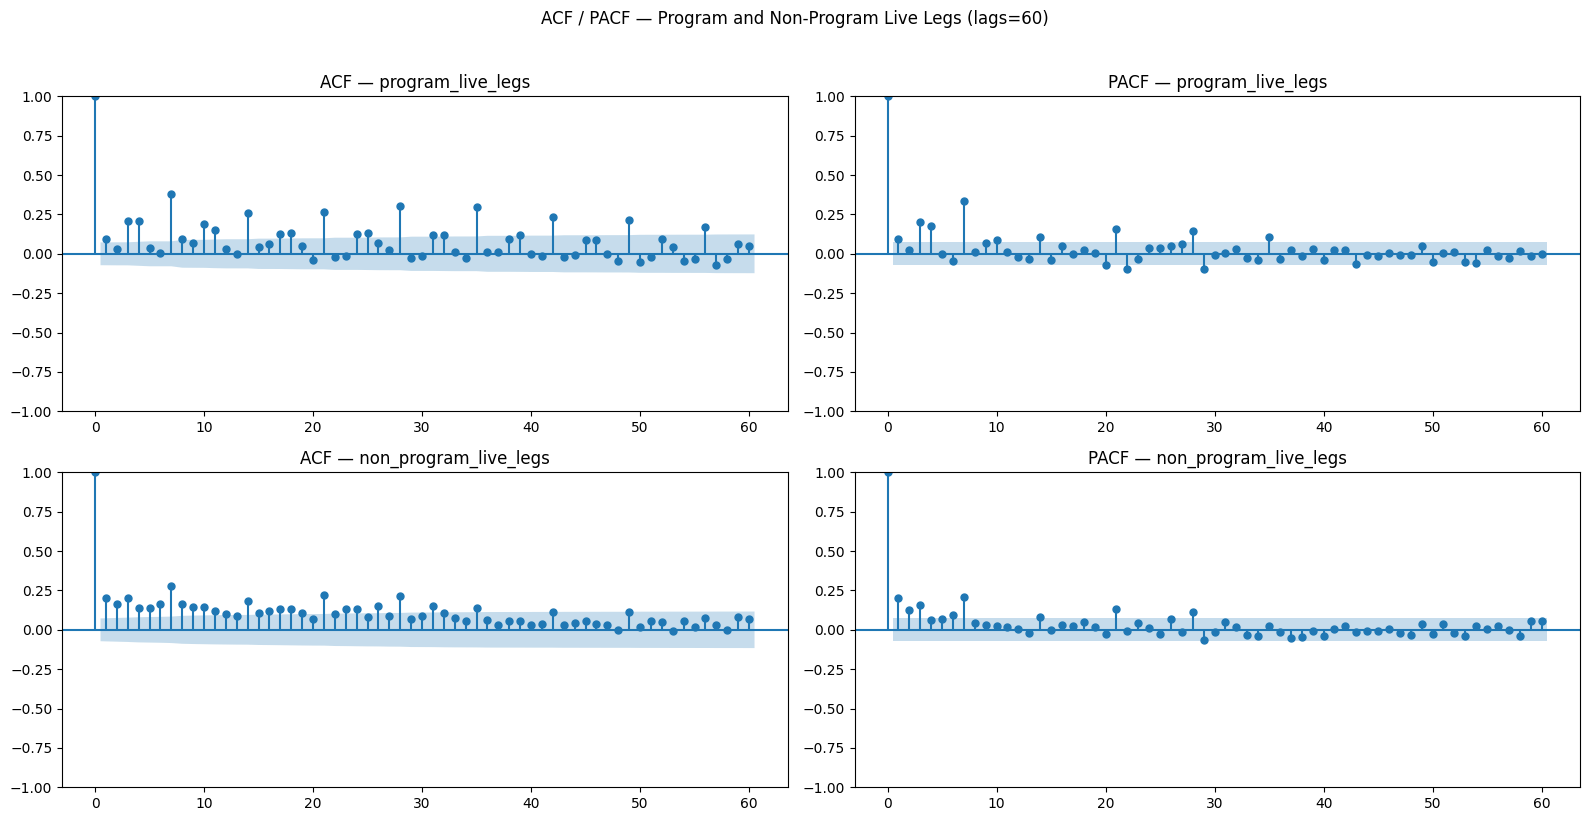


✅ Saved → data/processed/legs_fleet_daily.parquet


In [19]:
import matplotlib.pyplot as plt

# ── convert to pandas for statsmodels ACF/PACF ────────────────────
df_pd = df_daily.to_pandas()

TARGET_COLS  = ["program_live_legs", "non_program_live_legs", "cancellation_rate"]
COLORS       = ["#2563eb", "#d97706", "#dc2626"]

# ════════════════════════════════════════════════════════
# Section 5 — Time Series + 30-day Rolling Mean
# ════════════════════════════════════════════════════════
fig = go.Figure()

for col, color in zip(TARGET_COLS, COLORS):
    fig.add_trace(go.Scatter(
        x=df_pd["dep_date"], y=df_pd[col],
        mode="lines", name=col,
        line=dict(color=color, width=1), opacity=0.5
    ))
    rolling = df_pd[col].rolling(30, center=True).mean()
    fig.add_trace(go.Scatter(
        x=df_pd["dep_date"], y=rolling,
        mode="lines", name=f"{col} (30d avg)",
        line=dict(color=color, width=2.5, dash="dash")
    ))

fig.update_layout(
    title="Leg Counts + Cancellation Rate Over Time — NREG US (raw + 30d rolling mean)",
    xaxis_title="Departure Date", yaxis_title="Count / Rate",
    **PLOT_CFG
)
fig.show()

# ════════════════════════════════════════════════════════
# Section 6 — Monthly Seasonality Box Plots
# ════════════════════════════════════════════════════════
month_labels = ["Jan","Feb","Mar","Apr","May","Jun",
                "Jul","Aug","Sep","Oct","Nov","Dec"]

fig = make_subplots(rows=1, cols=3, subplot_titles=[
    "Program Live Legs by Month",
    "Non-Program Live Legs by Month",
    "Cancellation Rate by Month"
])

for idx, (col, color) in enumerate(zip(TARGET_COLS, COLORS)):
    for m in range(1, 13):
        vals = df_pd[df_pd["month"] == m][col].dropna().tolist()
        fig.add_trace(
            go.Box(y=vals, name=month_labels[m-1],
                   marker_color=color, showlegend=False),
            row=1, col=idx+1
        )

fig.update_layout(
    title="Monthly Seasonality — Leg Counts + Cancellation Rate",
    height=600, width=1200,
    margin=dict(l=50, r=50, t=80, b=50)
)
fig.show()

# ════════════════════════════════════════════════════════
# Section 7 — Day-of-Week Analysis
# ════════════════════════════════════════════════════════
dow_labels = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]

fig = make_subplots(rows=1, cols=3, subplot_titles=[
    "Program Live Legs by DOW",
    "Non-Program Live Legs by DOW",
    "Cancellation Rate by DOW"
])

for idx, (col, color) in enumerate(zip(TARGET_COLS, COLORS)):
    means = df_pd.groupby("day_of_week")[col].mean().reindex(range(7))
    fig.add_trace(
        go.Bar(x=dow_labels, y=means.values,
               marker_color=color, showlegend=False),
        row=1, col=idx+1
    )

fig.update_layout(
    title="Day-of-Week Effect — Leg Counts + Cancellation Rate",
    height=500, width=1200,
    margin=dict(l=50, r=50, t=80, b=50)
)
fig.show()

# ════════════════════════════════════════════════════════
# Section 8 — Cancellation Rate Deep Dive
# ════════════════════════════════════════════════════════

# 8a: overall cancellation rate by order type bucket
cancel_by_type = (
    df_labelled
    .filter(pl.col("IS_FERRY") == "Live")
    .with_columns(
        pl.when(pl.col("ORDER_TYPE") == "Program")
          .then(pl.lit("Program"))
          .otherwise(pl.lit("Non-Program"))
          .alias("order_bucket")
    )
    .group_by("order_bucket")
    .agg([
        pl.col("LEG_STATUS").eq("Cancelled").sum().alias("cancelled"),
        pl.len().alias("total")
    ])
    .with_columns(
        (pl.col("cancelled") / pl.col("total")).alias("cancel_rate")
    )
)
print("Cancellation rate by order bucket:")
print(cancel_by_type)

# 8b: callout distribution — how far in advance are live legs booked?
fig = make_subplots(rows=1, cols=2, subplot_titles=[
    "Callout Distribution — All Live Legs",
    "Cancellation Rate by Callout Bucket"
])

# callout histogram
callout_vals = df_labelled.filter(
    (pl.col("IS_FERRY") == "Live") &
    (pl.col("callout_days") <= 365)
)["callout_days"].to_list()

fig.add_trace(
    go.Histogram(x=callout_vals, nbinsx=50,
                 marker_color="#2563eb", name="callout distribution"),
    row=1, col=1
)

# callout buckets → cancellation rate
callout_buckets = (
    df_labelled
    .filter(
        (pl.col("IS_FERRY") == "Live") &
        (pl.col("callout_days") <= 365)
    )
    .with_columns(
        pl.when(pl.col("callout_days") <= 7).then(pl.lit("0-7d"))
        .when(pl.col("callout_days") <= 30).then(pl.lit("8-30d"))
        .when(pl.col("callout_days") <= 90).then(pl.lit("31-90d"))
        .when(pl.col("callout_days") <= 180).then(pl.lit("91-180d"))
        .otherwise(pl.lit("181d+"))
        .alias("callout_bucket")
    )
    .group_by("callout_bucket")
    .agg([
        pl.col("LEG_STATUS").eq("Cancelled").sum().alias("cancelled"),
        pl.len().alias("total")
    ])
    .with_columns(
        (pl.col("cancelled") / pl.col("total")).alias("cancel_rate")
    )
    .sort("callout_bucket")
)
print("\nCancellation rate by callout bucket:")
print(callout_buckets)

fig.add_trace(
    go.Bar(
        x=callout_buckets["callout_bucket"].to_list(),
        y=callout_buckets["cancel_rate"].to_list(),
        marker_color="#dc2626", name="cancel rate by callout"
    ),
    row=1, col=2
)

fig.update_layout(
    title="Callout Distribution + Cancellation Rate by Callout",
    height=500, width=1200,
    margin=dict(l=50, r=50, t=80, b=50)
)
fig.show()

# ════════════════════════════════════════════════════════
# Section 9 — ACF/PACF on program_live and non_program_live
# ════════════════════════════════════════════════════════
fig, axes = plt.subplots(2, 2, figsize=(16, 8))

for idx, col in enumerate(["program_live_legs", "non_program_live_legs"]):
    series = df_pd[col].dropna()
    sm.graphics.tsa.plot_acf(series, lags=60, ax=axes[idx, 0],
                              title=f"ACF — {col}")
    sm.graphics.tsa.plot_pacf(series, lags=60, ax=axes[idx, 1],
                               title=f"PACF — {col}")

plt.suptitle("ACF / PACF — Program and Non-Program Live Legs (lags=60)", y=1.02)
plt.tight_layout()
plt.savefig("../notebooks/acf_pacf_legs.png", dpi=150, bbox_inches="tight")
plt.show()

# ════════════════════════════════════════════════════════
# Section 10 — Save processed file
# ════════════════════════════════════════════════════════
df_daily.write_parquet(PROCESSED_DIR / "legs_fleet_daily.parquet")
print("\n✅ Saved → data/processed/legs_fleet_daily.parquet")

In [20]:
# ── cancellation lookup table (from training data only) ───────────
# Note: computed from ALL live legs (program + non-program combined)
# since the 2.5pp difference doesn't justify separate tables for MVP

df_train_legs = df_labelled.filter(
    (pl.col("IS_FERRY") == "Live") &
    (pl.col("dep_date") <= pl.lit("2025-09-30").str.to_date())
)

cancel_lookup = (
    df_train_legs
    .with_columns(
        pl.when(pl.col("callout_days") <= 7).then(pl.lit("0-7d"))
        .when(pl.col("callout_days") <= 30).then(pl.lit("8-30d"))
        .when(pl.col("callout_days") <= 90).then(pl.lit("31-90d"))
        .otherwise(pl.lit("91d+"))          # merged bucket
        .alias("callout_bucket")
    )
    .group_by("callout_bucket")
    .agg([
        pl.col("LEG_STATUS").eq("Cancelled").sum().alias("cancelled"),
        pl.len().alias("total")
    ])
    .with_columns(
        (pl.col("cancelled") / pl.col("total"))
        .round(4).alias("cancel_rate")
    )
    .sort("callout_bucket")
)

print("── Final Cancellation Rate Lookup Table (training data) ──")
print(cancel_lookup)

# save as dict for downstream use
cancel_lookup_dict = dict(
    zip(
        cancel_lookup["callout_bucket"].to_list(),
        cancel_lookup["cancel_rate"].to_list()
    )
)
print(f"\nLookup dict: {cancel_lookup_dict}")

# save to processed
import json
with open(PROCESSED_DIR / "cancellation_lookup.json", "w") as f:
    json.dump(cancel_lookup_dict, f, indent=2)
print("\n✅ Saved → data/processed/cancellation_lookup.json")

── Final Cancellation Rate Lookup Table (training data) ──
shape: (4, 4)
┌────────────────┬───────────┬───────┬─────────────┐
│ callout_bucket ┆ cancelled ┆ total ┆ cancel_rate │
│ ---            ┆ ---       ┆ ---   ┆ ---         │
│ str            ┆ u32       ┆ u32   ┆ f64         │
╞════════════════╪═══════════╪═══════╪═════════════╡
│ 0-7d           ┆ 1383      ┆ 8068  ┆ 0.1714      │
│ 31-90d         ┆ 1042      ┆ 4478  ┆ 0.2327      │
│ 8-30d          ┆ 1803      ┆ 10111 ┆ 0.1783      │
│ 91d+           ┆ 276       ┆ 831   ┆ 0.3321      │
└────────────────┴───────────┴───────┴─────────────┘

Lookup dict: {'0-7d': 0.1714, '31-90d': 0.2327, '8-30d': 0.1783, '91d+': 0.3321}

✅ Saved → data/processed/cancellation_lookup.json
